In [ ]:
#conecta ao Google Drive com as informações pertinentes da pesquisa
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
#uso das bibliotecas pandas (análise de dados), numpy (cálculos matemáticos), matplotlib, seaborn, plotly (gráficos)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
import matplotlib.gridspec as gridspec

In [ ]:
pd.set_option("display.max_columns", None)  # faz o pandas mostrar todas as colunas ao imprimir uma tabela
sns.set_theme(style="whitegrid")            # deixa os gráficos com fundo de grade, mais fácil de ler

In [ ]:
# biblioteca os  pra navegar/listar arquivos e pastas do sistema
import os

# caminho da pasta principal
PASTA_RAIZ = '/content/drive/Shareddrives/ENADE'

#Imprime cada pasta para confirmar os nomes exatos dos arquivos.
print("Pasta ENADE:", os.listdir(PASTA_RAIZ))
print("\n2014:", os.listdir(f'{PASTA_RAIZ}/2014'))
print("\n2017:", os.listdir(f'{PASTA_RAIZ}/2017'))
print("\n2019:", os.listdir(f'{PASTA_RAIZ}/2019'))
print("\n2023:", os.listdir(f'{PASTA_RAIZ}/2023'))

Pasta ENADE: ['disciplinaseca.xlsx', '2014', '2017', '2019', '2023', 'ENADE.gdoc', 'resumo_analise_ufop.xlsx', 'Resumo_Analise_UFOP (2).xlsx']

2014: ['2014decat.pdf', '2014.pdf', 'IGC_2014.xlsx', 'Conceito_Enade_2014.xlsx', 'CPC_2014.xlsx']

2017: ['2017decat.pdf', '2017.pdf', 'IGC_2017.xlsx', 'Conceito_Enade_2017.xlsx', 'IDD_2017.xlsx', 'CPC_2017.xlsx']

2019: ['IDD_2019.xlsx', 'IGC_2019.xlsx', 'decat2019.pdf', 'Conceito_Enade_2019.xlsx', 'CPC_2019.xlsx']

2023: ['IDD_2023.xlsx', '2023decat.pdf', 'CPC_2023.xlsx', 'IGC_2023.xlsx', 'Conceito_Enade_2023.xlsx']


In [ ]:
#Caminhos para as pastas de cada ano
CAMINHO_2014 = f'{PASTA_RAIZ}/2014'
CAMINHO_2017 = f'{PASTA_RAIZ}/2017'
CAMINHO_2019 = f'{PASTA_RAIZ}/2019'
CAMINHO_2023 = f'{PASTA_RAIZ}/2023'

def carregar_planilha_inteligente(caminho):
    # Lê todas as abas do arquivo excel
    xls = pd.ExcelFile(caminho)

    aba_dados = None
    for aba in xls.sheet_names:
        if "ATUALIZA" not in aba.upper() and "CAPA" not in aba.upper():
            aba_dados = aba
            break

    if aba_dados is None:
        aba_dados = 0

    return pd.read_excel(caminho, sheet_name=aba_dados)

#IGC (índice Geral do Curso, de 1 a 5), mede a qualidade do curso e da intituição de ensino
igc_2023 = pd.read_excel(f'{CAMINHO_2023}/IGC_2023.xlsx', sheet_name=0)
igc_2019 = pd.read_excel(f'{CAMINHO_2019}/IGC_2019.xlsx', sheet_name=0)
igc_2017 = pd.read_excel(f'{CAMINHO_2017}/IGC_2017.xlsx', sheet_name=0)
igc_2014 = pd.read_excel(f'{CAMINHO_2014}/IGC_2014.xlsx', sheet_name=0)

#CPC (Conceito Preliminar de Curso, de 1 a 5) é o indicador mais completo,
#junta nota do Enade + IDD + corpo docente (mestres/doutores) + infraestrutura
cpc_2023 = pd.read_excel(f'{CAMINHO_2023}/CPC_2023.xlsx', sheet_name=0)
cpc_2019 = pd.read_excel(f'{CAMINHO_2019}/CPC_2019.xlsx', sheet_name=0)
cpc_2017 = pd.read_excel(f'{CAMINHO_2017}/CPC_2017.xlsx', sheet_name=0)
cpc_2014 = pd.read_excel(f'{CAMINHO_2014}/CPC_2014.xlsx', sheet_name=0)

#Conceito Enade é só a nota final do exame em si, de 1 a 5
enade_2023 = pd.read_excel(f'{CAMINHO_2023}/Conceito_Enade_2023.xlsx', sheet_name=0)
enade_2019 = pd.read_excel(f'{CAMINHO_2019}/Conceito_Enade_2019.xlsx', sheet_name=0)
enade_2017 = pd.read_excel(f'{CAMINHO_2017}/Conceito_Enade_2017.xlsx', sheet_name=0)
enade_2014 = pd.read_excel(f'{CAMINHO_2014}/Conceito_Enade_2014.xlsx', sheet_name=0)

#IDD mede o quanto o curso "agregou" ao aluno - compara a nota que ele já
#tinha no Enem (entrada) com a nota que tirou no Enade (saída)
idd_2023 = pd.read_excel(f'{CAMINHO_2023}/IDD_2023.xlsx', sheet_name=0)
idd_2019 = pd.read_excel(f'{CAMINHO_2019}/IDD_2019.xlsx', sheet_name=0)
idd_2017 = pd.read_excel(f'{CAMINHO_2017}/IDD_2017.xlsx', sheet_name=0)

In [ ]:
import pandas as pd

# 1. Definição do caminho raiz no Google Drive
PASTA_RAIZ = "/content/drive/Shareddrives/ENADE"

# 2. Mapeamento das planilhas de origem (CPC de cada ano)
ARQUIVOS_CPC = {
    2014: f"{PASTA_RAIZ}/2014/CPC_2014.xlsx",
    2017: f"{PASTA_RAIZ}/2017/CPC_2017.xlsx",
    2019: f"{PASTA_RAIZ}/2019/CPC_2019.xlsx",
    2023: f"{PASTA_RAIZ}/2023/CPC_2023.xlsx",
}


def extrair_desempenho_ufop(caminho_excel, ano):
    """Lê a planilha do ano correspondente, busca a linha da UFOP para

    Engenharia de Controle e Automação e extrai os indicadores principais.
    """
    # Lê a primeira aba da planilha
    df = pd.read_excel(caminho_excel, sheet_name=0)

    # Limpa espaços invisíveis nos nomes das colunas
    df.columns = df.columns.str.strip()

    # 1. Filtro do Curso: Procura por 'CONTROLE E AUTOMA' ou pelo código do curso (5814)
    mascara_curso = pd.Series(False, index=df.index)
    for col in df.columns:
        vals = df[col].astype(str).str.upper()
        mascara_curso = (
            mascara_curso
            | vals.str.contains("CONTROLE E AUTOMA", na=False)
            | (vals == "5814")
        )

    # 2. Filtro da Instituição: Procura por 'OURO PRETO'
    mascara_ufop = pd.Series(False, index=df.index)
    for col in df.columns:
        mascara_ufop = mascara_ufop | df[col].astype(
            str
        ).str.upper().str.contains("OURO PRETO", na=False)

    # Aplica os dois filtros combinados
    df_filtrado = df[mascara_curso & mascara_ufop].copy()

    if df_filtrado.empty:
        return pd.DataFrame()

    # Dicionário para armazenar as métricas capturadas
    dados = {"Ano": ano}

    # Varre as colunas dinamicamente para extrair os indicadores
    for col in df_filtrado.columns:
        col_up = str(col).upper()

        if "CPC" in col_up and "CONT" in col_up:
            dados["CPC (Contínuo)"] = pd.to_numeric(
                df_filtrado[col].values[0], errors="coerce"
            )
        elif "CPC" in col_up and "FAIXA" in col_up:
            dados["CPC (Faixa)"] = df_filtrado[col].values[0]
        elif "ENADE" in col_up and "CONT" in col_up:
            dados["Conceito ENADE (Contínuo)"] = pd.to_numeric(
                df_filtrado[col].values[0], errors="coerce"
            )
        elif "PADRONIZADA" in col_up and "IDD" in col_up:
            dados["Nota Padronizada - IDD"] = pd.to_numeric(
                df_filtrado[col].values[0], errors="coerce"
            )
        elif "BRUTA" in col_up and "CE" in col_up:
            dados["Nota Bruta - CE"] = pd.to_numeric(
                df_filtrado[col].values[0], errors="coerce"
            )

    return pd.DataFrame([dados])


# 3. Execução da extração ano a ano e consolidação em uma única tabela
registros = []
for ano, caminho in ARQUIVOS_CPC.items():
    df_ano = extrair_desempenho_ufop(caminho, ano)
    if not df_ano.empty:
        registros.append(df_ano)

# Cria a tabela consolidada
tabela_ufop = pd.concat(registros, ignore_index=True)

# Exibe a tabela formatada com 3 casas decimais
display(tabela_ufop.round(3))

,Ano,Nota Bruta - CE,Conceito ENADE (Contínuo),Nota Padronizada - IDD,CPC (Contínuo),CPC (Faixa)
0,2014,45.587,3.074,2.449,3.046,4
1,2017,39.871,2.726,2.413,2.983,4
2,2019,39.072,2.844,2.435,3.195,4
3,2023,39.500,2.887,1.399,2.969,4


In [ ]:
CURSO_ALVO = 'ENGENHARIA DE CONTROLE E AUTOMAÇÃO'
ESTADOS_SUDESTE = ['SP', 'RJ', 'MG', 'ES']

def filtrar_forca_bruta(df):
    if df.empty: return df

    # 1. FILTRO DE CURSO (BUSCA EM TODAS AS COLUNAS)
    mascara_curso = pd.Series(False, index=df.index)
    for c in df.columns:
        valores = df[c].astype(str).str.upper()
        # Procura pelo nome ou pelo código oficial do MEC/INEP para o curso (5814)
        mascara_curso = mascara_curso | valores.str.contains('CONTROLE E AUTOMA', na=False) | (valores == '5814')

    if not mascara_curso.any():
        return pd.DataFrame(columns=df.columns) # Retorna vazio se não achar o curso

    # Aplica o filtro de curso
    df = df[mascara_curso].copy()

    # 2. FILTRO DE ESTADO (SUDESTE)
    mascara_uf = pd.Series(False, index=df.index)
    for c in df.columns:
        # Foca nas colunas que parecem ser de localização
        if any(palavra in str(c).upper() for palavra in ['UF', 'ESTADO', 'SIGLA']):
            valores_uf = df[c].astype(str).str.strip().str.upper()
            mascara_uf = mascara_uf | valores_uf.isin(ESTADOS_SUDESTE)

    if not mascara_uf.any():
        return pd.DataFrame(columns=df.columns)

    return df[mascara_uf].copy()

# --- APLICANDO A FORÇA BRUTA ---
cpc_2023 = filtrar_forca_bruta(cpc_2023)
enade_2023 = filtrar_forca_bruta(enade_2023)
idd_2023 = filtrar_forca_bruta(idd_2023)

cpc_2019 = filtrar_forca_bruta(cpc_2019)
enade_2019 = filtrar_forca_bruta(enade_2019)
idd_2019 = filtrar_forca_bruta(idd_2019)

cpc_2017 = filtrar_forca_bruta(cpc_2017)
enade_2017 = filtrar_forca_bruta(enade_2017)
idd_2017 = filtrar_forca_bruta(idd_2017)

cpc_2014 = filtrar_forca_bruta(cpc_2014)
enade_2014 = filtrar_forca_bruta(enade_2014)

# --- PADRONIZANDO O NOME DO CPC EM 2014 ---
if 'CPC Contínuo' in cpc_2014.columns:
    cpc_2014 = cpc_2014.rename(columns={'CPC Contínuo': 'CPC (Contínuo)'})

print('Filtro aplicado!')

Filtro aplicado!


In [ ]:
import numpy as np
import pandas as pd

# Dicionários com as tabelas originais já carregadas no seu notebook
cpc_anos = {2014: cpc_2014, 2017: cpc_2017, 2019: cpc_2019, 2023: cpc_2023}
igc_anos = {2014: igc_2014, 2017: igc_2017, 2019: igc_2019, 2023: igc_2023}
idd_anos = {2014: pd.DataFrame(), 2017: idd_2017, 2019: idd_2019, 2023: idd_2023}
enade_anos = {
    2014: enade_2014,
    2017: enade_2017,
    2019: enade_2019,
    2023: enade_2023,
}


def achar_coluna(df, palavras_obrigatorias, palavras_proibidas=[]):
    """Auxiliar para encontrar colunas com variação de nome nos arquivos do INEP."""
    if df.empty:
        return None
    for col in df.columns:
        c_up = str(col).upper()
        if all(p in c_up for p in palavras_obrigatorias):
            if not any(p in c_up for p in palavras_proibidas):
                return col
    return None


registros_mg = []

for ano in [2014, 2017, 2019, 2023]:
    df_cpc = cpc_anos[ano]
    if df_cpc.empty:
        continue

    # 1. Identifica a coluna de UF que contém 'MG'
    col_uf = None
    for c in df_cpc.columns:
        if (df_cpc[c].astype(str).str.strip().str.upper() == "MG").any():
            col_uf = c
            break

    # 2. Filtra cursos de Controle e Automação em MG
    mascara_curso = pd.Series(False, index=df_cpc.index)
    for c in df_cpc.columns:
        vals = df_cpc[c].astype(str).str.upper()
        mascara_curso |= vals.str.contains("CONTROLE E AUTOMA", na=False) | (
            vals == "5814"
        )

    mascara_mg = (
        df_cpc[col_uf].astype(str).str.strip().str.upper() == "MG"
        if col_uf
        else pd.Series(False, index=df_cpc.index)
    )

    df_mg = df_cpc[mascara_curso & mascara_mg].copy()
    if df_mg.empty:
        continue

    # Mapeamento dinâmico das colunas do CPC
    col_ies = achar_coluna(
        df_mg, ["NOME"], ["CURSO"]
    ) or achar_coluna(df_mg, ["IES"])
    col_cod_ies = achar_coluna(df_mg, ["CÓDIGO", "IES"])
    col_cpc_cont = achar_coluna(df_mg, ["CPC", "CONT"])
    col_cpc_faix = achar_coluna(df_mg, ["CPC", "FAIXA"])

    # Mapeamento do IGC do ano
    df_igc = igc_anos[ano]
    col_igc_cod = achar_coluna(df_igc, ["CÓDIGO", "IES"])
    col_igc_cont = achar_coluna(df_igc, ["IGC", "CONT"])

    # Mapeamento do IDD do ano
    df_idd = idd_anos[ano]
    col_idd_cod = achar_coluna(df_idd, ["CÓDIGO", "IES"]) or achar_coluna(
        df_idd, ["CÓDIGO", "CURSO"]
    )
    col_idd_cont = achar_coluna(df_idd, ["IDD", "CONT"]) or achar_coluna(
        df_idd, ["PADRONIZADA", "IDD"]
    )

    # Mapeamento do Conceito ENADE do ano
    df_ena = enade_anos[ano]
    col_ena_cod = achar_coluna(df_ena, ["CÓDIGO", "IES"]) or achar_coluna(
        df_ena, ["CÓDIGO", "CURSO"]
    )
    col_ena_cont = achar_coluna(df_ena, ["ENADE", "CONT"]) or achar_coluna(
        df_ena, ["CONCEITO", "CONT"]
    )

    for idx, row in df_mg.iterrows():
        nome_ies = row[col_ies] if col_ies else "UNIVERSIDADE FEDERAL DE OURO PRETO"
        cod_ies = row[col_cod_ies] if col_cod_ies else None

        # Busca IGC da instituição
        val_igc = np.nan
        if not df_igc.empty and col_igc_cod and col_igc_cont and cod_ies:
            match_igc = df_igc[df_igc[col_igc_cod] == cod_ies]
            if not match_igc.empty:
                val_igc = match_igc[col_igc_cont].values[0]

        # Busca IDD do curso/IES
        val_idd = np.nan
        if not df_idd.empty and col_idd_cont:
            val_idd = row.get(
                achar_coluna(df_mg, ["PADRONIZADA", "IDD"]), np.nan
            )

        # Busca Conceito ENADE
        val_ena = np.nan
        if not df_ena.empty and col_ena_cont:
            val_ena = row.get(
                achar_coluna(df_mg, ["ENADE", "CONT"]), np.nan
            )

        registros_mg.append(
            {
                "Ano": ano,
                "Instituição": nome_ies,
                "CPC (Contínuo)": pd.to_numeric(
                    row.get(col_cpc_cont), errors="coerce"
                ),
                "CPC (Faixa)": row.get(col_cpc_faix),
                "IGC (Contínuo)": pd.to_numeric(val_igc, errors="coerce"),
                "IDD (Padronizado/Cont.)": pd.to_numeric(
                    val_idd, errors="coerce"
                ),
                "Conceito ENADE (Contínuo)": pd.to_numeric(
                    val_ena, errors="coerce"
                ),
            }
        )

# Consolida a tabela completa
tabela_mg = pd.DataFrame(registros_mg)


# Função de estilização para negritar a linha da UFOP
def destacar_ufop(row):
    is_ufop = "OURO PRETO" in str(row["Instituição"]).upper()
    return [
        "font-weight: bold; background-color: #fef08a; color: #000000"
        if is_ufop
        else ""
        for _ in row
    ]


# Aplica a formatação na exibição do Colab
tabela_mg_estilizada = (
    tabela_mg.sort_values(["Ano", "CPC (Contínuo)"], ascending=[True, False])
    .reset_index(drop=True)
    .style.apply(destacar_ufop, axis=1)
    .format(
        {
            "CPC (Contínuo)": "{:.3f}",
            "IGC (Contínuo)": "{:.3f}",
            "IDD (Padronizado/Cont.)": "{:.3f}",
            "Conceito ENADE (Contínuo)": "{:.3f}",
        },
        na_rep="-",
    )
)

display(tabela_mg_estilizada)

,Ano,Instituição,CPC (Contínuo),CPC (Faixa),IGC (Contínuo),IDD (Padronizado/Cont.),Conceito ENADE (Contínuo)
0,2014,UNIVERSIDADE FEDERAL DE MINAS GERAIS,4.141,5,-,-,4.311
1,2014,UNIVERSIDADE FEDERAL DE UBERLÂNDIA,3.544,4,-,-,2.989
2,2014,UNIVERSIDADE FEDERAL DE ITAJUBÁ - UNIFEI,3.407,4,-,-,4.199
3,2014,UNIVERSIDADE FEDERAL DE ITAJUBÁ - UNIFEI,3.347,4,-,-,3.917
4,2014,UNIVERSIDADE FEDERAL DE OURO PRETO,3.046,4,-,-,3.074
5,2014,FACULDADE DE CIÊNCIA E TECNOLOGIA DE MONTES CLAROS,2.873,3,-,-,2.403
6,2014,CENTRO UNIVERSITÁRIO UNA,2.774,3,-,-,2.333
7,2014,CENTRO FEDERAL DE EDUCAÇÃO TECNOLÓGICA DE MINAS GERAIS,2.773,3,-,-,2.378
8,2014,UNIVERSIDADE FEDERAL DE LAVRAS,2.724,3,-,-,2.638
9,2014,FACULDADE PITÁGORAS DE BELO HORIZONTE,2.556,3,-,-,1.297


In [ ]:
# 1. Recarregar apenas as bases originais do CPC (que já contêm o Enade e IDD)
cpc_2023 = carregar_planilha_inteligente(f'{CAMINHO_2023}/CPC_2023.xlsx')
cpc_2019 = carregar_planilha_inteligente(f'{CAMINHO_2019}/CPC_2019.xlsx')
cpc_2017 = carregar_planilha_inteligente(f'{CAMINHO_2017}/CPC_2017.xlsx')
cpc_2014 = carregar_planilha_inteligente(f'{CAMINHO_2014}/CPC_2014.xlsx')

# 2. Aplicar a função de filtro de força bruta
cpc_2023 = filtrar_forca_bruta(cpc_2023)
cpc_2019 = filtrar_forca_bruta(cpc_2019)
cpc_2017 = filtrar_forca_bruta(cpc_2017)
cpc_2014 = filtrar_forca_bruta(cpc_2014)

# 3. Padronizar o nome da coluna do CPC em 2014 para a concatenação não falhar
if 'CPC Contínuo' in cpc_2014.columns:
    cpc_2014 = cpc_2014.rename(columns={'CPC Contínuo': 'CPC (Contínuo)'})

# 4. Verificar os resultados reais
print("--- Quantidade de cursos de Automação no Sudeste (Tabelas Consolidadas) ---")
print("CPC 2023:", len(cpc_2023))
print("CPC 2019:", len(cpc_2019))
print("CPC 2017:", len(cpc_2017))
print("CPC 2014:", len(cpc_2014))

--- Quantidade de cursos de Automação no Sudeste (Tabelas Consolidadas) ---
CPC 2023: 97
CPC 2019: 119
CPC 2017: 115
CPC 2014: 83


In [ ]:
print("--- Quantidade de cursos de Automação no Sudeste ---")

print("CPC 2023:", len(cpc_2023))
print("Enade 2023:", len(enade_2023))
print("IDD 2023:", len(idd_2023))
print("-" * 30)

print("CPC 2019:", len(cpc_2019))
print("Enade 2019:", len(enade_2019))
print("IDD 2019:", len(idd_2019))
print("-" * 30)

print("CPC 2017:", len(cpc_2017))
print("Enade 2017:", len(enade_2017))
print("IDD 2017:", len(idd_2017))
print("-" * 30)

print("CPC 2014:", len(cpc_2014))
print("Enade 2014:", len(enade_2014))

print("\nVerificação concluída!")

--- Quantidade de cursos de Automação no Sudeste ---
CPC 2023: 97
Enade 2023: 97
IDD 2023: 97
------------------------------
CPC 2019: 119
Enade 2019: 119
IDD 2019: 119
------------------------------
CPC 2017: 115
Enade 2017: 115
IDD 2017: 115
------------------------------
CPC 2014: 83
Enade 2014: 83

Verificação concluída!


In [ ]:
REGIAO = {
    "ES": "Sudeste",
    "MG": "Sudeste",
    "RJ": "Sudeste",
    "SP": "Sudeste"
}

def adicionar_regiao(df):
    """
    Procura a coluna de Estado (UF) e cria uma nova coluna chamada 'Região'
    baseada no dicionário REGIAO.
    """
    if df.empty: return df

    col_uf = None
    for c in df.columns:
        if str(c).strip().upper() in ['SIGLA DA UF', 'SG_UF', 'UF', 'SIGLA UF', 'UF_IES']:
            col_uf = c
            break

    if col_uf:
        # Cria a nova coluna 'Região' mapeando a sigla do estado
        df['Região'] = df[col_uf].map(REGIAO)

    return df

# Aplicando a nova coluna nas bases principais (CPC)
cpc_2023 = adicionar_regiao(cpc_2023)
cpc_2019 = adicionar_regiao(cpc_2019)
cpc_2017 = adicionar_regiao(cpc_2017)
cpc_2014 = adicionar_regiao(cpc_2014)

print("Coluna 'Região' adicionada com sucesso nas tabelas de CPC!")

Coluna 'Região' adicionada com sucesso nas tabelas de CPC!


In [ ]:
import pandas as pd

# Mapeamento dos DataFrames brutos (originais) e filtrados (Sudeste) por ano
dados_anos = {
    2014: {
        "bruto": carregar_planilha_inteligente(
            f"{CAMINHO_2014}/CPC_2014.xlsx"
        ),
        "sudeste": cpc_2014,
    },
    2017: {
        "bruto": carregar_planilha_inteligente(
            f"{CAMINHO_2017}/CPC_2017.xlsx"
        ),
        "sudeste": cpc_2017,
    },
    2019: {
        "bruto": carregar_planilha_inteligente(
            f"{CAMINHO_2019}/CPC_2019.xlsx"
        ),
        "sudeste": cpc_2019,
    },
    2023: {
        "bruto": carregar_planilha_inteligente(
            f"{CAMINHO_2023}/CPC_2023.xlsx"
        ),
        "sudeste": cpc_2023,
    },
}

registros_contagem = []

for ano, df_dict in dados_anos.items():
    df_bruto = df_dict["bruto"]
    df_sudeste = df_dict["sudeste"]

    # 1. Total Geral do Brasil (Número de cursos avaliados no ciclo)
    qtd_brasil = len(df_bruto) if not df_bruto.empty else 0

    # 2. Total da Região Sudeste (Já filtrado anteriormente na sua base)
    qtd_sudeste = len(df_sudeste) if not df_sudeste.empty else 0

    # 3. Total em Minas Gerais (MG)
    qtd_mg = 0
    if not df_sudeste.empty:
        # Localiza a coluna de UF dentro da base do Sudeste
        col_uf = next(
            (
                c
                for c in df_sudeste.columns
                if (
                    df_sudeste[c].astype(str).str.strip().str.upper() == "MG"
                ).any()
            ),
            None,
        )
        if col_uf:
            qtd_mg = len(
                df_sudeste[
                    df_sudeste[col_uf].astype(str).str.strip().str.upper()
                    == "MG"
                ]
            )

    registros_contagem.append(
        {
            "Ano": ano,
            "Cursos no Brasil (Geral CPC)": qtd_brasil,
            "Cursos na Região Sudeste": qtd_sudeste,
            "Cursos em Minas Gerais (MG)": qtd_mg,
        }
    )

# Consolida e exibe a tabela comparativa de contagem
df_qtd_cursos = pd.DataFrame(registros_contagem)
display(df_qtd_cursos)

,Ano,Cursos no Brasil (Geral CPC),Cursos na Região Sudeste,Cursos em Minas Gerais (MG)
0,2014,8959,83,19
1,2017,10570,115,26
2,2019,8368,119,29
3,2023,9812,97,26


In [ ]:
# Usa o .copy() para garantir que estamos trabalhando em tabelas independentes,

# 2023
cpc_2023 = cpc_2023.copy()
cpc_2023["Ano"] = 2023

# 2019
cpc_2019 = cpc_2019.copy()
cpc_2019["Ano"] = 2019

# 2017
cpc_2017 = cpc_2017.copy()
cpc_2017["Ano"] = 2017

# 2014
cpc_2014 = cpc_2014.copy()
cpc_2014["Ano"] = 2014

In [ ]:
def extrair_colunas_essenciais(df, ano):
    if df.empty: return pd.DataFrame()

    dados = {'Ano': ano}

    # Busca flexível do Código da IES
    for c in df.columns:
        if 'CÓDIGO' in str(c).upper() and 'IES' in str(c).upper():
            dados['Código da IES'] = df[c].values
            break

    # Busca flexível da Nota Bruta do CE
    for c in df.columns:
        if 'BRUTA' in str(c).upper() and 'CE' in str(c).upper():
            dados['Nota Bruta - CE'] = df[c].values
            break

    # Busca flexível da Nota do IDD
    for c in df.columns:
        if 'PADRONIZADA' in str(c).upper() and 'IDD' in str(c).upper():
            dados['Nota Padronizada - IDD'] = df[c].values
            break

    # Busca flexível do CPC Contínuo
    for c in df.columns:
        if 'CPC' in str(c).upper() and 'CONT' in str(c).upper():
            dados['CPC (Contínuo)'] = df[c].values
            break

    # Mantém a Região que você criou no passo anterior
    if 'Região' in df.columns:
        dados['Região'] = df['Região'].values

    return pd.DataFrame(dados)

# Aplica a extração
df_2023 = extrair_colunas_essenciais(cpc_2023, 2023)
df_2019 = extrair_colunas_essenciais(cpc_2019, 2019)
df_2017 = extrair_colunas_essenciais(cpc_2017, 2017)
df_2014 = extrair_colunas_essenciais(cpc_2014, 2014)

print("Colunas essenciais extraídas e padronizadas com sucesso!")

Colunas essenciais extraídas e padronizadas com sucesso!


In [ ]:
base_geral = pd.concat([df_2014, df_2017, df_2019, df_2023], ignore_index=True)

# Converte notas para numérico (transformando "SC" ou "*" em vazio)
col_notas = ["Nota Bruta - CE", "Nota Padronizada - IDD", "CPC (Contínuo)"]

for col in col_notas:
    if col in base_geral.columns:
        base_geral[col] = pd.to_numeric(base_geral[col], errors="coerce")

print("Base unificada e notas convertidas para números!")
print("Dimensões da Base Geral (Linhas, Colunas):", base_geral.shape)

Base unificada e notas convertidas para números!
Dimensões da Base Geral (Linhas, Colunas): (414, 6)


In [ ]:
evolucao = base_geral.groupby("Ano").agg(
    cpc_medio=("CPC (Contínuo)", "mean"),
    idd_medio=("Nota Padronizada - IDD", "mean"),
    nota_ce_bruta_media=("Nota Bruta - CE", "mean"),
    qtd_cursos=("Código da IES", "count")
).round(3)

print("=== Evolução Histórica (Região Sudeste) ===")
print(evolucao)

=== Evolução Histórica (Região Sudeste) ===
      cpc_medio  idd_medio  nota_ce_bruta_media  qtd_cursos
Ano                                                        
2014      2.536      2.258               36.103          83
2017      2.565      2.394               33.960         115
2019      2.612      2.409               33.805         119
2023      2.669      2.075               36.248          97


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Resgata o IGC contínuo da UFOP diretamente das planilhas de IGC carregadas
igc_valores = {}
for ano, df_igc in {
    2014: igc_2014,
    2017: igc_2017,
    2019: igc_2019,
    2023: igc_2023,
}.items():
  # Localiza a linha da UFOP no IGC
  mask = df_igc.apply(
      lambda row: row.astype(str).str.upper().str.contains("OURO PRETO").any(),
      axis=1,
  )
  col_igc = next(
      (c for c in df_igc.columns if "IGC" in str(c).upper() and "CONT" in str(c).upper()),
      None,
  )
  if mask.any() and col_igc:
    igc_valores[ano] = pd.to_numeric(
        df_igc.loc[mask, col_igc].values[0], errors="coerce"
    )
  else:
    igc_valores[ano] = np.nan

# Cria cópia da tabela de indicadores da UFOP e adiciona a coluna de IGC
df_ufop_completo = tabela_ufop.copy()
df_ufop_completo["IGC (Contínuo)"] = df_ufop_completo["Ano"].map(igc_valores)

# Função auxiliar para padronizar e plotar cada gráfico
def plotar_indicador_ufop(
    df, coluna_y, titulo, ylabel, ylim=(0, 5), palette="Blues_d"
):
  plt.figure(figsize=(7, 4.5))
  ax = sns.barplot(
      data=df,
      x="Ano",
      y=coluna_y,
      hue="Ano",
      palette=palette,
      legend=False,
  )

  for p in ax.patches:
    altura = p.get_height()
    if not np.isnan(altura) and altura > 0:
      ax.annotate(
          f"{altura:.2f}",
          (p.get_x() + p.get_width() / 2.0, altura),
          ha="center",
          va="bottom",
          fontsize=10,
          fontweight="bold",
          xytext=(0, 3),
          textcoords="offset points",
      )

  plt.title(titulo, fontsize=12, pad=15, fontweight="bold")
  plt.xlabel("Ano do Ciclo", fontsize=11)
  plt.ylabel(ylabel, fontsize=11)
  plt.ylim(ylim)
  plt.tight_layout()
  plt.show()

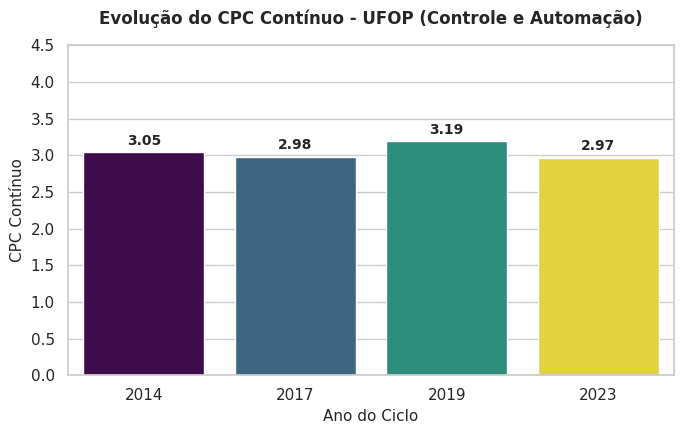

In [ ]:
plotar_indicador_ufop(
    df=df_ufop_completo,
    coluna_y="CPC (Contínuo)",
    titulo="Evolução do CPC Contínuo - UFOP (Controle e Automação)",
    ylabel="CPC Contínuo",
    ylim=(0, 4.5),
    palette="viridis",
)

In [ ]:
# Tabela com as notas e subcomponentes da UFOP em Controle e Automação
def extrair_detalhes_ufop(df, ano):
    if df.empty:
        return pd.DataFrame()

    mascara_curso = pd.Series(False, index=df.index)
    for col in df.columns:
        vals = df[col].astype(str).str.upper()
        mascara_curso |= vals.str.contains('CONTROLE E AUTOMA', na=False) | (vals == '5814')

    mascara_ufop = pd.Series(False, index=df.index)
    for col in df.columns:
        mascara_ufop |= df[col].astype(str).str.upper().str.contains('OURO PRETO', na=False)

    df_f = df[mascara_curso & mascara_ufop].copy()
    if df_f.empty:
        return pd.DataFrame()

    dados = {'Ano': ano}
    for col in df_f.columns:
        c_up = str(col).upper()
        if 'CPC' in c_up and 'CONT' in c_up:
            dados['CPC Contínuo'] = pd.to_numeric(df_f[col].values[0], errors='coerce')
        elif 'CPC' in c_up and 'FAIXA' in c_up:
            dados['CPC Faixa'] = df_f[col].values[0]
        elif 'ENADE' in c_up and 'CONT' in c_up:
            dados['Conceito ENADE'] = pd.to_numeric(df_f[col].values[0], errors='coerce')
        elif 'IDD' in c_up and ('PADRONIZADA' in c_up or 'CONT' in c_up):
            dados['Nota IDD'] = pd.to_numeric(df_f[col].values[0], errors='coerce')
        elif 'DOCENTE' in c_up or 'MESTRES' in c_up or 'DOUTORES' in c_up:
            dados['Corpo Docente'] = pd.to_numeric(df_f[col].values[0], errors='coerce')
        elif 'INFRAESTRUTURA' in c_up or 'INSTALA' in c_up:
            dados['Infraestrutura'] = pd.to_numeric(df_f[col].values[0], errors='coerce')

    return pd.DataFrame([dados])

tabela_ufop_detalhes = pd.concat([
    extrair_detalhes_ufop(cpc_2014, 2014),
    extrair_detalhes_ufop(cpc_2017, 2017),
    extrair_detalhes_ufop(cpc_2019, 2019),
    extrair_detalhes_ufop(cpc_2023, 2023)
], ignore_index=True)

display(tabela_ufop_detalhes.round(3))

,Ano,Conceito ENADE,Infraestrutura,Nota IDD,Corpo Docente,CPC Contínuo,CPC Faixa
0,2014,3.074,2.627,2.449,3.289,3.046,4
1,2017,2.726,2.767,2.413,3.492,2.983,4
2,2019,2.844,2.409,2.435,4.385,3.195,4
3,2023,2.887,3.475,1.399,4.500,2.969,4


In [ ]:
# Compara a UFOP com as outras Instituições Públicas Federais de Minas Gerais
registros_federais = []

for ano, df_cpc in cpc_anos.items():
    if df_cpc.empty:
        continue

    col_uf = next((c for c in df_cpc.columns if (df_cpc[c].astype(str).str.strip().str.upper() == 'MG').any()), None)
    col_cpc = next((c for c in df_cpc.columns if 'CPC' in str(c).upper() and 'CONT' in str(c).upper()), None)
    col_cat = next((c for c in df_cpc.columns if 'CATEGORIA' in str(c).upper() or 'ADMINISTRATIVA' in str(c).upper()), None)
    col_ies = next((c for c in df_cpc.columns if any(p in str(c).upper() for p in ['NOME DA IES', 'INSTITUIÇÃO', 'NOME DO CURSO'])), None)

    if not (col_uf and col_cpc):
        continue

    df_mg = df_cpc[df_cpc[col_uf].astype(str).str.strip().str.upper() == 'MG'].copy()
    df_mg['CPC_num'] = pd.to_numeric(df_mg[col_cpc], errors='coerce')

    # Filtra linha da UFOP
    mask_ufop = df_mg[col_ies].astype(str).str.upper().str.contains('OURO PRETO', na=False) if col_ies else pd.Series(False, index=df_mg.index)
    nota_ufop = df_mg.loc[mask_ufop, 'CPC_num'].values[0] if mask_ufop.any() else np.nan

    # Média das Federais de MG
    if col_cat:
        mask_fed = df_mg[col_cat].astype(str).str.upper().str.contains('FEDERAL', na=False)
        media_federais = df_mg.loc[mask_fed, 'CPC_num'].mean()
    else:
        media_federais = np.nan

    registros_federais.append({
        'Ano': ano,
        'CPC UFOP': nota_ufop,
        'Média Federais MG': media_federais,
        'Diferença (UFOP - Federais)': nota_ufop - media_federais if not np.isnan(media_federais) else np.nan
    })

tabela_comparativo_federais = pd.DataFrame(registros_federais)
display(tabela_comparativo_federais.round(3))

,Ano,CPC UFOP,Média Federais MG,Diferença (UFOP - Federais)
0,2014,3.046,3.179,-0.133
1,2017,2.983,3.136,-0.153
2,2019,3.195,3.345,-0.150
3,2023,2.969,3.274,-0.306


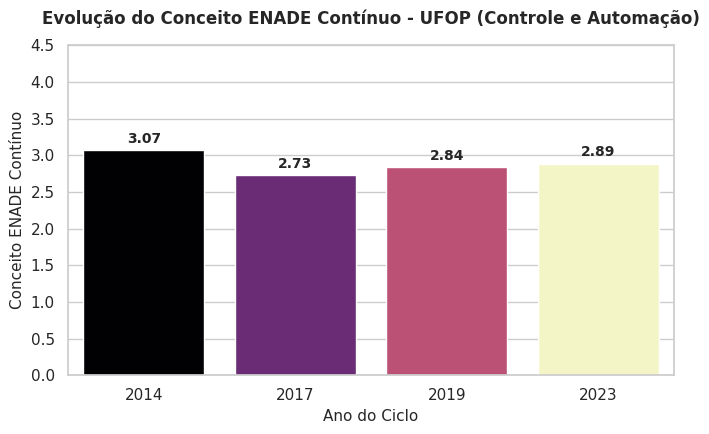

In [ ]:
plotar_indicador_ufop(
    df=df_ufop_completo,
    coluna_y="Conceito ENADE (Contínuo)",
    titulo="Evolução do Conceito ENADE Contínuo - UFOP (Controle e Automação)",
    ylabel="Conceito ENADE Contínuo",
    ylim=(0, 4.5),
    palette="magma",
)

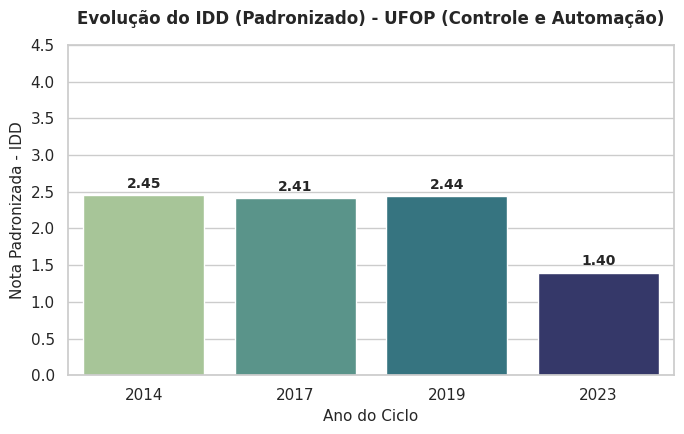

In [ ]:
plotar_indicador_ufop(
    df=df_ufop_completo,
    coluna_y="Nota Padronizada - IDD",
    titulo="Evolução do IDD (Padronizado) - UFOP (Controle e Automação)",
    ylabel="Nota Padronizada - IDD",
    ylim=(0, 4.5),
    palette="crest",
)

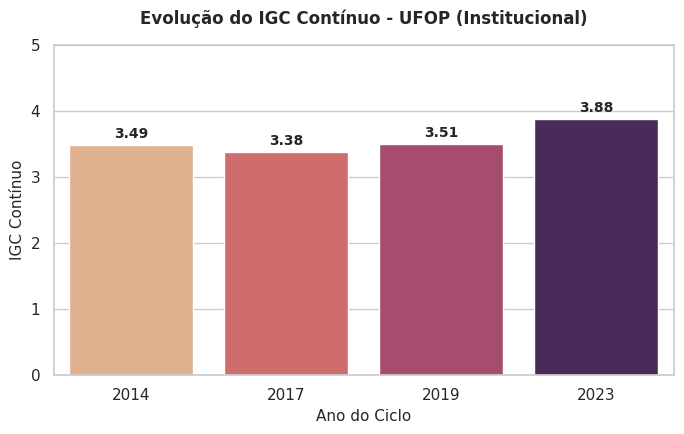

In [ ]:
plotar_indicador_ufop(
    df=df_ufop_completo,
    coluna_y="IGC (Contínuo)",
    titulo="Evolução do IGC Contínuo - UFOP (Institucional)",
    ylabel="IGC Contínuo",
    ylim=(0, 5.0),
    palette="flare",
)

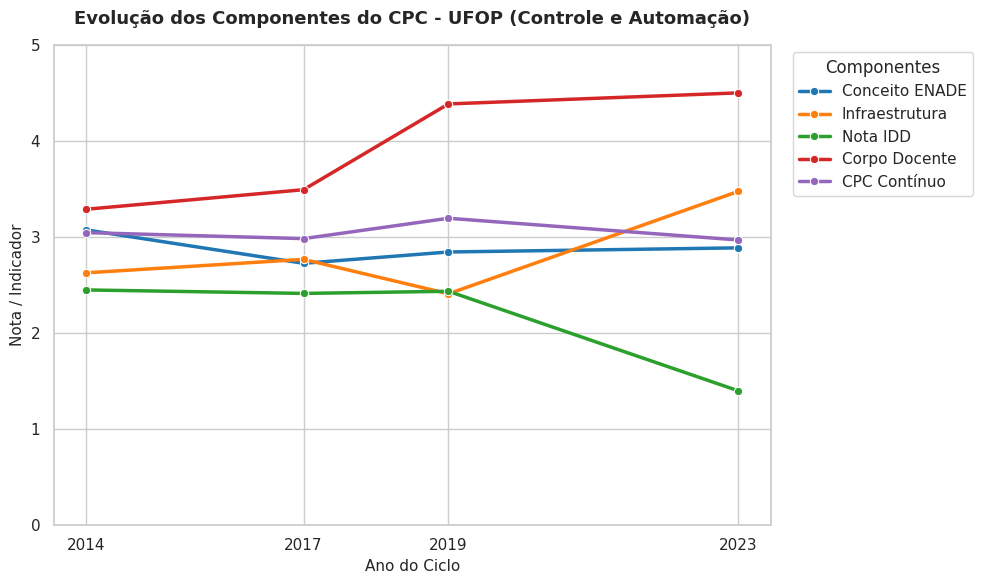

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Transforma a tabela para o formato longo (long-form), ideal para o seaborn
colunas_metricas = [
    col
    for col in tabela_ufop_detalhes.columns
    if col not in ["Ano", "CPC Faixa"]
]
df_plot_detalhes = tabela_ufop_detalhes.melt(
    id_vars="Ano",
    value_vars=colunas_metricas,
    var_name="Componente",
    value_name="Nota",
)

plt.figure(figsize=(10, 6))

ax = sns.lineplot(
    data=df_plot_detalhes,
    x="Ano",
    y="Nota",
    hue="Componente",
    marker="o",
    linewidth=2.5,
    palette="tab10",
)

plt.title(
    "Evolução dos Componentes do CPC - UFOP (Controle e Automação)",
    fontsize=13,
    pad=15,
    fontweight="bold",
)
plt.xlabel("Ano do Ciclo", fontsize=11)
plt.ylabel("Nota / Indicador", fontsize=11)
plt.xticks(tabela_ufop_detalhes["Ano"].unique())  # Garante os anos 2014, 2017, 2019 e 2023
plt.ylim(0, 5.0)

# Posiciona a legenda para fora do gráfico para não cobrir as linhas
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", title="Componentes")

plt.tight_layout()
plt.show()

In [ ]:
por_regiao = base_geral.groupby(["Região", "Ano"]).agg(
    cpc_medio=("CPC (Contínuo)", "mean"),
    qtd_cursos=("Código da IES", "count"),  # Utiliza Código da IES para evitar KeyError
).round(3).reset_index()

print("=== Agrupamento por Região e Ano ===")
print(por_regiao)

=== Agrupamento por Região e Ano ===
    Região   Ano  cpc_medio  qtd_cursos
0  Sudeste  2017      2.565         115
1  Sudeste  2019      2.612         119
2  Sudeste  2023      2.669          97


In [ ]:
# Preenche a Região como 'Sudeste' em todas as linhas da base
base_geral["Região"] = "Sudeste"


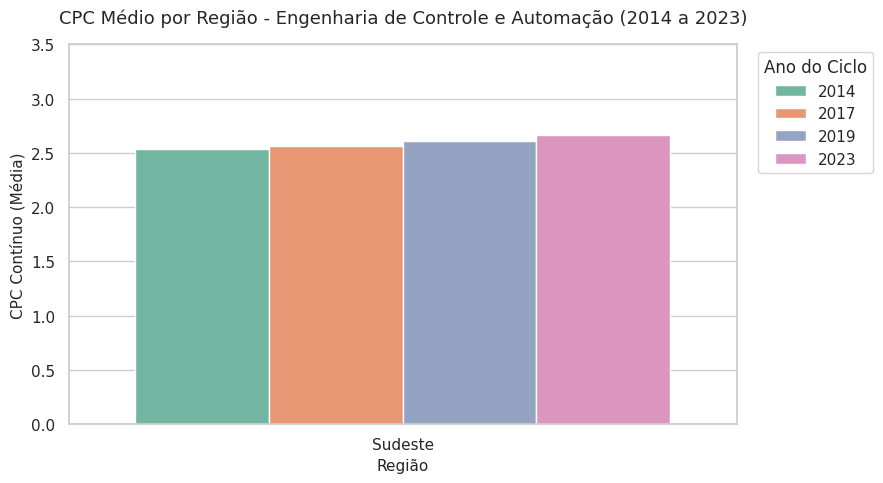

In [ ]:
plt.figure(figsize=(9, 5))

# Como a base tem os 4 anos (2014 a 2023), o hue="Ano" vai criar 4 barras lado a lado
sns.barplot(
    data=base_geral,
    x="Região",
    y="CPC (Contínuo)",
    hue="Ano",
    estimator=np.mean,
    errorbar=None,        # Deixa as barras limpas sem as linhas de desvio
    palette="Set2"
)

# Atualiza o título para o período histórico completo da pesquisa
plt.title("CPC Médio por Região - Engenharia de Controle e Automação (2014 a 2023)", fontsize=13, pad=15)
plt.xlabel("Região", fontsize=11)
plt.ylabel("CPC Contínuo (Média)", fontsize=11)
plt.ylim(0, 3.5)

# Posiciona a legenda para não cobrir o gráfico
plt.legend(title="Ano do Ciclo", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()
plt.show()

In [ ]:
def extrair_dados_ufop(df, ano):
    if df.empty:
        return pd.DataFrame()

    # 1. Localizar a linha da UFOP procurando por 'OURO PRETO' em todas as colunas de texto
    mascara_ufop = pd.Series(False, index=df.index)
    for c in df.columns:
        mascara_ufop = mascara_ufop | df[c].astype(str).str.upper().str.contains("OURO PRETO", na=False)

    df_ufop = df[mascara_ufop].copy()
    if df_ufop.empty:
        return pd.DataFrame()

    dados = {"Ano": ano}

    # 2. Resgatar as métricas principais de forma flexível
    for c in df_ufop.columns:
        col_upper = str(c).upper()
        if "CPC" in col_upper and "CONT" in col_upper:
            dados["CPC (Contínuo)"] = pd.to_numeric(df_ufop[c].values[0], errors="coerce")
        elif "CPC" in col_upper and "FAIXA" in col_upper:
            dados["CPC (Faixa)"] = df_ufop[c].values[0]
        elif "PADRONIZADA" in col_upper and "IDD" in col_upper:
            dados["Nota Padronizada - IDD"] = pd.to_numeric(df_ufop[c].values[0], errors="coerce")
        elif "ENADE" in col_upper and "CONT" in col_upper:
            dados["Conceito Enade (Contínuo)"] = pd.to_numeric(df_ufop[c].values[0], errors="coerce")
        elif "BRUTA" in col_upper and "CE" in col_upper:
            dados["Nota Bruta - CE"] = pd.to_numeric(df_ufop[c].values[0], errors="coerce")

    return pd.DataFrame([dados])

# Consolidação do histórico da UFOP
ufop_historico = pd.concat([
    extrair_dados_ufop(cpc_2014, 2014),
    extrair_dados_ufop(cpc_2017, 2017),
    extrair_dados_ufop(cpc_2019, 2019),
    extrair_dados_ufop(cpc_2023, 2023)
], ignore_index=True)

print("=== Desempenho Histórico: UFOP (Engenharia de Controle e Automação) ===")
print(ufop_historico.round(3))

=== Desempenho Histórico: UFOP (Engenharia de Controle e Automação) ===
    Ano  Nota Bruta - CE  Conceito Enade (Contínuo)  Nota Padronizada - IDD  \
0  2014           45.587                      3.074                   2.449   
1  2017           39.871                      2.726                   2.413   
2  2019           39.072                      2.844                   2.435   
3  2023           39.500                      2.887                   1.399   

   CPC (Contínuo) CPC (Faixa)  
0           3.046           4  
1           2.983           4  
2           3.195           4  
3           2.969           4  


In [ ]:
bases_ano = {
    2014: cpc_2014,
    2017: cpc_2017,
    2019: cpc_2019,
    2023: cpc_2023
}

comparacao = []

for ano, df_ano in bases_ano.items():
    if df_ano.empty:
        continue

    # 1. Identifica a coluna correta de UF (procura a coluna que contém 'MG')
    col_uf = None
    for c in df_ano.columns:
        valores_texto = df_ano[c].astype(str).str.strip().str.upper()
        if (valores_texto == "MG").any():
            col_uf = c
            break

    # 2. Identifica a coluna de CPC Contínuo
    col_cpc = next((c for c in df_ano.columns if "CPC" in str(c).upper() and "CONT" in str(c).upper()), None)

    # Converte o CPC para formato numérico
    cpc_numerico = pd.to_numeric(df_ano[col_cpc], errors="coerce")

    # Filtro da UFOP
    mascara_ufop = pd.Series(False, index=df_ano.index)
    for c in df_ano.columns:
        mascara_ufop = mascara_ufop | df_ano[c].astype(str).str.upper().str.contains("OURO PRETO", na=False)

    # Filtro de Minas Gerais usando a coluna localizada
    if col_uf is not None:
        mascara_mg = df_ano[col_uf].astype(str).str.strip().str.upper() == "MG"
    else:
        mascara_mg = pd.Series(False, index=df_ano.index)

    comparacao.append({
        "Ano": ano,
        "UFOP": cpc_numerico[mascara_ufop].mean(),
        "Média MG": cpc_numerico[mascara_mg].mean(),
        "Média Sudeste": cpc_numerico.mean()
    })

df_comparacao = pd.DataFrame(comparacao)

print("=== Comparativo Histórico de CPC Contínuo ===")
print(df_comparacao.round(3))

=== Comparativo Histórico de CPC Contínuo ===
    Ano   UFOP  Média MG  Média Sudeste
0  2014  3.046     2.802          2.536
1  2017  2.983     2.858          2.565
2  2019  3.195     2.829          2.612
3  2023  2.969     3.004          2.669


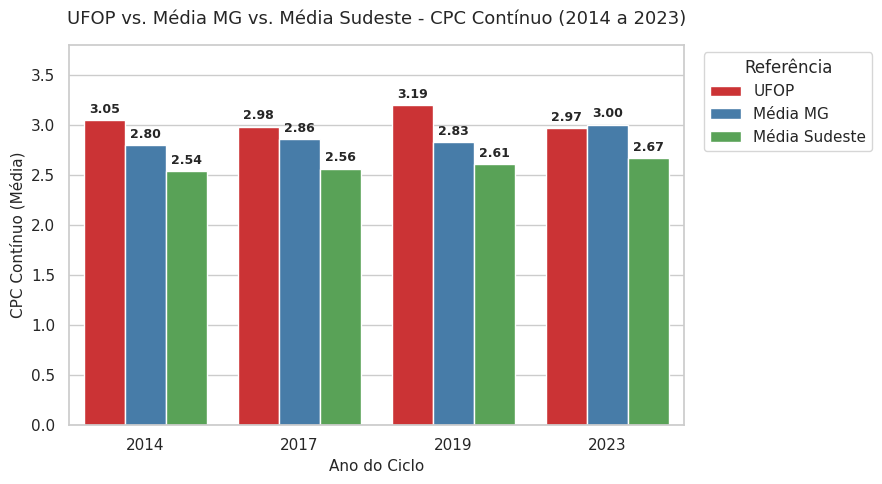

In [ ]:
comparacao_plot = df_comparacao.melt(
    id_vars="Ano",
    var_name="Referência",
    value_name="CPC médio"
)

plt.figure(figsize=(9, 5))

# Plotagem em barras agrupadas por Ano
ax = sns.barplot(
    data=comparacao_plot,
    x="Ano",
    y="CPC médio",
    hue="Referência",
    palette="Set1"
)

# Adiciona os rótulos de valores no topo das barras
for p in ax.patches:
    altura = p.get_height()
    if not np.isnan(altura) and altura > 0:
        ax.annotate(
            f"{altura:.2f}",
            (p.get_x() + p.get_width() / 2., altura),
            ha="center",
            va="bottom",
            fontsize=9,
            fontweight="bold",
            xytext=(0, 3),
            textcoords="offset points"
        )

# Título ajustado com o recorte geográfico real dos dados (Sudeste)
plt.title("UFOP vs. Média MG vs. Média Sudeste - CPC Contínuo (2014 a 2023)", fontsize=13, pad=15)
plt.xlabel("Ano do Ciclo", fontsize=11)
plt.ylabel("CPC Contínuo (Média)", fontsize=11)
plt.ylim(0, 3.8)

# Posiciona a legenda fora da área de dados
plt.legend(title="Referência", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()
plt.show()

In [ ]:
bases_ano = {
    2014: cpc_2014,
    2017: cpc_2017,
    2019: cpc_2019,
    2023: cpc_2023
}

print("=== Ranking do Curso da UFOP em Minas Gerais (CPC Contínuo) ===")

for ano, df_ano in bases_ano.items():
    if df_ano.empty:
        continue

    # 1. Encontra a coluna de UF (procura a coluna que possui 'MG')
    col_uf = None
    for c in df_ano.columns:
        valores_texto = df_ano[c].astype(str).str.strip().str.upper()
        if (valores_texto == "MG").any():
            col_uf = c
            break

    # 2. Encontra a coluna de CPC Contínuo
    col_cpc = next((c for c in df_ano.columns if "CPC" in str(c).upper() and "CONT" in str(c).upper()), None)

    # 3. Encontra a coluna de Nome da IES
    col_ies = next((c for c in df_ano.columns if any(p in str(c).upper() for p in ["NOME DA IES", "NOME DO CURSO", "INSTITUIÇÃO"])), None)

    # Filtra apenas o estado de Minas Gerais
    mascara_mg = df_ano[col_uf].astype(str).str.strip().str.upper() == "MG"
    mg_ano = df_ano[mascara_mg].copy()

    # Converte notas para numérico e ordena do maior para o menor CPC
    mg_ano["CPC_num"] = pd.to_numeric(mg_ano[col_cpc], errors="coerce")
    mg_ano = mg_ano.dropna(subset=["CPC_num"]).sort_values("CPC_num", ascending=False).reset_index(drop=True)
    mg_ano["Posição em MG"] = mg_ano.index + 1

    # Busca a linha da UFOP
    mascara_ufop = pd.Series(False, index=mg_ano.index)
    for c in mg_ano.columns:
        mascara_ufop = mascara_ufop | mg_ano[c].astype(str).str.upper().str.contains("OURO PRETO", na=False)

    posicao_ufop = mg_ano[mascara_ufop]
    total_mg = len(mg_ano)

    if not posicao_ufop.empty:
        pos = posicao_ufop["Posição em MG"].values[0]
        nota = posicao_ufop["CPC_num"].values[0]
        print(f"UFOP em {ano}: {pos}º lugar de {total_mg} cursos em MG (CPC Contínuo: {nota:.3f})")
    else:
        print(f"UFOP em {ano}: Não localizada no ranking de MG")

=== Ranking do Curso da UFOP em Minas Gerais (CPC Contínuo) ===
UFOP em 2014: 5º lugar de 16 cursos em MG (CPC Contínuo: 3.046)
UFOP em 2017: 13º lugar de 25 cursos em MG (CPC Contínuo: 2.983)
UFOP em 2019: 10º lugar de 29 cursos em MG (CPC Contínuo: 3.195)
UFOP em 2023: 12º lugar de 23 cursos em MG (CPC Contínuo: 2.969)


In [ ]:
bases_ano = {
    2014: cpc_2014,
    2017: cpc_2017,
    2019: cpc_2019,
    2023: cpc_2023
}

registros_estados = []

for ano, df_ano in bases_ano.items():
    if df_ano.empty:
        continue

    # 1. Localiza a coluna de UF que contém as siglas dos estados
    col_uf = None
    for c in df_ano.columns:
        valores_texto = df_ano[c].astype(str).str.strip().str.upper()
        if (valores_texto == "MG").any():
            col_uf = c
            break

    # 2. Localiza a coluna de CPC Contínuo
    col_cpc = next((c for c in df_ano.columns if "CPC" in str(c).upper() and "CONT" in str(c).upper()), None)

    # 3. Localiza uma coluna identificadora de curso/IES para contagem
    col_id = next((c for c in df_ano.columns if any(p in str(c).upper() for p in ["CÓDIGO", "IES", "CURSO"])), df_ano.columns[0])

    if col_uf and col_cpc:
        df_temp = pd.DataFrame({
            "Ano": ano,
            "Sigla da UF": df_ano[col_uf].astype(str).str.strip().str.upper(),
            "CPC (Contínuo)": pd.to_numeric(df_ano[col_cpc], errors="coerce"),
            "ID": df_ano[col_id]
        })
        registros_estados.append(df_temp)

df_estados_completo = pd.concat(registros_estados, ignore_index=True)

# Filtra apenas os estados do Sudeste válidos
df_estados_completo = df_estados_completo[df_estados_completo["Sigla da UF"].isin(["SP", "MG", "RJ", "ES"])]

# Agrupa por estado e ano
por_estado = df_estados_completo.groupby(["Sigla da UF", "Ano"]).agg(
    cpc_medio=("CPC (Contínuo)", "mean"),
    qtd_cursos=("ID", "count")
).round(3).reset_index()

print("=== CPC Médio e Quantidade de Cursos por Estado (Sudeste) ===")
print(por_estado)

=== CPC Médio e Quantidade de Cursos por Estado (Sudeste) ===
   Sigla da UF   Ano  cpc_medio  qtd_cursos
0           ES  2014      3.308           2
1           ES  2017      2.887           4
2           ES  2019      3.255           4
3           ES  2023      2.890           3
4           MG  2014      2.802          19
5           MG  2017      2.858          26
6           MG  2019      2.829          29
7           MG  2023      3.004          26
8           RJ  2014      2.890           7
9           RJ  2017      2.637          10
10          RJ  2019      2.663          11
11          RJ  2023      2.647          12
12          SP  2014      2.374          55
13          SP  2017      2.436          75
14          SP  2019      2.480          75
15          SP  2023      2.510          56


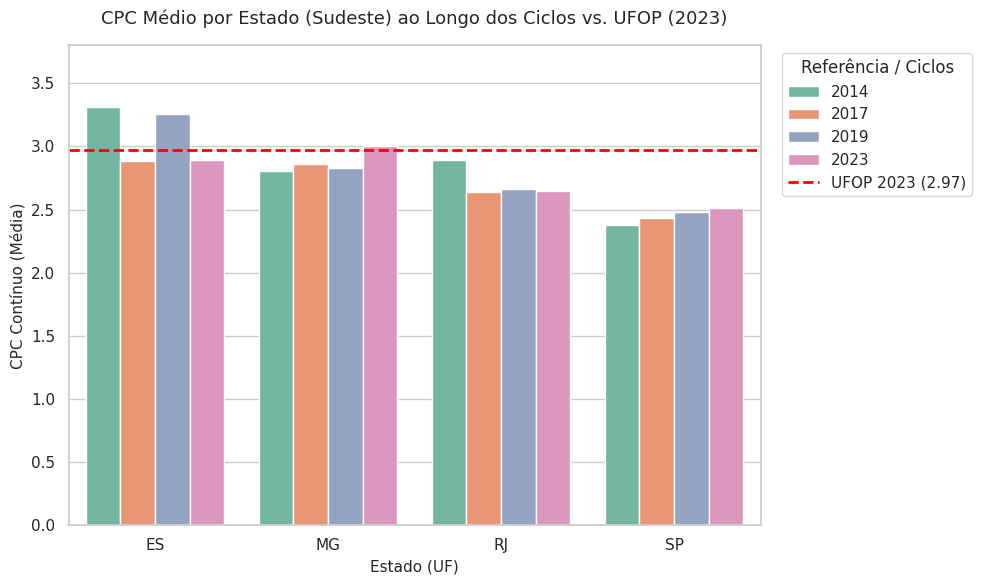

In [ ]:
# 1. Resgata a nota de 2023 da UFOP obtida na Etapa 17
cpc_ufop_2023 = ufop_historico[ufop_historico["Ano"] == 2023]["CPC (Contínuo)"].values[0]

plt.figure(figsize=(10, 6))

# 2. Ordena os estados pela maior média histórica geral
ordem_estados = (
    df_estados_completo.groupby("Sigla da UF")["CPC (Contínuo)"]
    .mean()
    .sort_values(ascending=False)
    .index
)

# 3. Gráfico de barras agrupadas por Ano para cada Estado
ax = sns.barplot(
    data=df_estados_completo,
    x="Sigla da UF",
    y="CPC (Contínuo)",
    hue="Ano",
    order=ordem_estados,
    estimator=np.mean,
    errorbar=None,
    palette="Set2"
)

# 4. Linha de referência horizontal da UFOP em 2023
plt.axhline(
    cpc_ufop_2023,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"UFOP 2023 ({cpc_ufop_2023:.2f})"
)

# Títulos, eixos e posicionamento da legenda
plt.title("CPC Médio por Estado (Sudeste) ao Longo dos Ciclos vs. UFOP (2023)", fontsize=13, pad=15)
plt.xlabel("Estado (UF)", fontsize=11)
plt.ylabel("CPC Contínuo (Média)", fontsize=11)
plt.ylim(0, 3.8)

plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", title="Referência / Ciclos")

plt.tight_layout()
plt.show()

In [ ]:
# 1. Localizar as colunas essenciais na tabela bruta de 2023
col_uf = next(c for c in cpc_2023.columns if (cpc_2023[c].astype(str).str.strip().str.upper() == "MG").any())
col_cpc_cont = next(c for c in cpc_2023.columns if "CPC" in str(c).upper() and "CONT" in str(c).upper())
col_cpc_faixa = next(c for c in cpc_2023.columns if "CPC" in str(c).upper() and "FAIXA" in str(c).upper())
col_ies = next(c for c in cpc_2023.columns if "NOME DA IES" in str(c).upper() or "INSTITUIÇÃO" in str(c).upper())
col_municipio = next(c for c in cpc_2023.columns if "MUNIC" in str(c).upper() or "CIDADE" in str(c).upper())
col_cat = next(c for c in cpc_2023.columns if "CATEGORIA" in str(c).upper() or "ADMINISTRATIVA" in str(c).upper())

# 2. Filtrar apenas os cursos de Minas Gerais
mascara_mg = cpc_2023[col_uf].astype(str).str.strip().str.upper() == "MG"
mg_2023_detalhado = cpc_2023[mascara_mg].copy()

# 3. Converter notas e ordenar
mg_2023_detalhado["CPC (Contínuo)"] = pd.to_numeric(mg_2023_detalhado[col_cpc_cont], errors="coerce")
mg_2023_detalhado = mg_2023_detalhado.sort_values("CPC (Contínuo)", ascending=False).reset_index(drop=True)

# 4. Selecionar e renomear as colunas desejadas
top5_mg = mg_2023_detalhado.head(5)[[
    col_ies,
    col_municipio,
    col_cat,
    "CPC (Contínuo)",
    col_cpc_faixa
]].copy()

top5_mg.columns = [
    "Nome da IES",
    "Município do Curso",
    "Categoria Administrativa",
    "CPC (Contínuo)",
    "CPC (Faixa)"
]

print("Top 5 Cursos de Engenharia de Controle e Automação em MG (2023)")
display(top5_mg)

Top 5 Cursos de Engenharia de Controle e Automação em MG (2023)


,Nome da IES,Município do Curso,Categoria Administrativa,CPC (Contínuo),CPC (Faixa)
0,UNIVERSIDADE FEDERAL DE ITAJUBÁ - UNIFEI,3132404,Pública Federal,3.860,4
1,UNIVERSIDADE FEDERAL DE MINAS GERAIS,3106200,Pública Federal,3.814,4
2,UNIVERSIDADE FEDERAL DE UBERLÂNDIA,3170206,Pública Federal,3.789,4
3,UNIVERSIDADE FEDERAL DE ITAJUBÁ - UNIFEI,3131703,Pública Federal,3.643,4
4,INSTITUTO NACIONAL DE TELECOMUNICAÇÕES,3159605,Privada sem fins lucrativos,3.533,4


In [ ]:
resumo_categoria_mg = mg_2023_detalhado.groupby(col_cat)["CPC (Contínuo)"].agg(["count", "mean"]).round(3)
resumo_categoria_mg.columns = ["Qtd. Cursos", "CPC Contínuo Médio"]
print("\n=== Desempenho por Categoria Administrativa em MG (2023) ===")
display(resumo_categoria_mg)


=== Desempenho por Categoria Administrativa em MG (2023) ===


,Qtd. Cursos,CPC Contínuo Médio
Categoria Administrativa,,
Comunitária/Confessional,1,2.801
Privada com fins lucrativos,6,2.779
Privada sem fins lucrativos,4,2.579
Pública Federal,12,3.274


/tmp/ipykernel_3257/1562249153.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


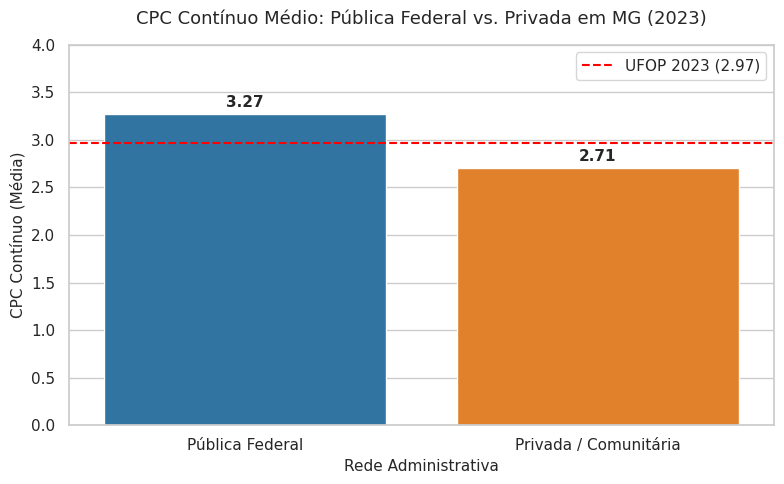

In [ ]:
# 1. Ajustar a coluna de Município buscando pelo nome textual
col_mun_nome = next((c for c in cpc_2023.columns if "MUNIC" in str(c).upper() and "CÓD" not in str(c).upper()), None)
if col_mun_nome:
    top5_mg["Município do Curso"] = mg_2023_detalhado.head(5)[col_mun_nome].values

# 2. Simplificar as categorias para "Pública Federal" vs "Privada / Comunitária"
mg_2023_detalhado["Tipo_Rede"] = mg_2023_detalhado[col_cat].apply(
    lambda x: "Pública Federal" if "Pública" in str(x) else "Privada / Comunitária"
)

plt.figure(figsize=(8, 5))
ax = sns.barplot(
    data=mg_2023_detalhado,
    x="Tipo_Rede",
    y="CPC (Contínuo)",
    estimator=np.mean,
    errorbar=None,
    palette=["#1f77b4", "#ff7f0e"]
)

# Adiciona linha de referência da UFOP
plt.axhline(2.969, color="red", linestyle="--", linewidth=1.5, label="UFOP 2023 (2.97)")

# Rótulos de média nas barras
for p in ax.patches:
    altura = p.get_height()
    if not np.isnan(altura):
        ax.annotate(f"{altura:.2f}", (p.get_x() + p.get_width() / 2., altura),
                    ha="center", va="bottom", fontsize=11, fontweight="bold", xytext=(0, 3), textcoords="offset points")

plt.title("CPC Contínuo Médio: Pública Federal vs. Privada em MG (2023)", fontsize=13, pad=15)
plt.xlabel("Rede Administrativa", fontsize=11)
plt.ylabel("CPC Contínuo (Média)", fontsize=11)
plt.ylim(0, 4.0)
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()

In [ ]:
bases_ano = {
    2014: cpc_2014,
    2017: cpc_2017,
    2019: cpc_2019,
    2023: cpc_2023
}

def achar_coluna(df, palavras_obrigatorias, palavras_proibidas=[]):
    for col in df.columns:
        c_upper = str(col).upper()
        if all(p in c_upper for p in palavras_obrigatorias):
            if not any(p in c_upper for p in palavras_proibidas):
                return col
    return None

dados_corrigidos = []

for ano, df_ano in bases_ano.items():
    if df_ano.empty:
        continue

    # Linha da UFOP
    mascara_ufop = pd.Series(False, index=df_ano.index)
    for c in df_ano.columns:
        mascara_ufop = mascara_ufop | df_ano[c].astype(str).str.upper().str.contains("OURO PRETO", na=False)

    linha_ufop = df_ano[mascara_ufop]
    if linha_ufop.empty:
        continue

    # Mapeamento flexível por palavras-chave
    col_cpc = achar_coluna(df_ano, ["CPC", "CONT"])
    col_ce = achar_coluna(df_ano, ["PADRONIZADA", "ESPEC"], ["GERAL"]) or achar_coluna(df_ano, ["PADRONIZADA", "CE"])
    col_idd = achar_coluna(df_ano, ["PADRONIZADA", "IDD"]) or achar_coluna(df_ano, ["IDD", "CONT"])
    col_didat = achar_coluna(df_ano, ["DIDAT"], ["BRUT"]) or achar_coluna(df_ano, ["ORGANIZA"], ["BRUT"])
    col_infra = achar_coluna(df_ano, ["INFRA"], ["BRUT"])
    col_amplia = achar_coluna(df_ano, ["AMPLIA"], ["BRUT"]) or achar_coluna(df_ano, ["OPORTUN"], ["BRUT"])
    col_mest = achar_coluna(df_ano, ["MEST"], ["BRUT"])
    col_dout = achar_coluna(df_ano, ["DOUT"], ["BRUT"])
    col_regime = achar_coluna(df_ano, ["REGIME"], ["BRUT"]) or achar_coluna(df_ano, ["TRABALHO"], ["BRUT"])

    def extrair_val(col):
        if col:
            v = pd.to_numeric(linha_ufop[col].values[0], errors="coerce")
            # Se a nota docente estiver em proporção (0 a 1), converte para a escala 0 a 5
            if pd.notnull(v) and v <= 1.0 and ("MEST" in col.upper() or "DOUT" in col.upper() or "REGIME" in col.upper()):
                return v * 5.0
            return v
        return np.nan

    dados_corrigidos.append({
        "Ano": ano,
        "CPC (Contínuo)": extrair_val(col_cpc),
        "Nota Padronizada - CE": extrair_val(col_ce),
        "Nota Padronizada - IDD": extrair_val(col_idd),
        "Nota Padronizada - Didático-Pedagógica": extrair_val(col_didat),
        "Nota Padronizada - Infraestrutura": extrair_val(col_infra),
        "Nota Padronizada - Ampliação da Formação": extrair_val(col_amplia),
        "Nota Padronizada - Mestres": extrair_val(col_mest),
        "Nota Padronizada - Doutores": extrair_val(col_dout),
        "Nota Padronizada - Regime de Trabalho": extrair_val(col_regime),
    })

insumos_ufop = pd.DataFrame(dados_corrigidos).sort_values("Ano").reset_index(drop=True)
display(insumos_ufop.round(3))

,Ano,CPC (Contínuo),Nota Padronizada - CE,Nota Padronizada - IDD,Nota Padronizada - Didático-Pedagógica,Nota Padronizada - Infraestrutura,Nota Padronizada - Ampliação da Formação,Nota Padronizada - Mestres,Nota Padronizada - Doutores,Nota Padronizada - Regime de Trabalho
0,2014,3.046,NaN,2.449,NaN,2.627,3.565,4.275,3.289,5.0
1,2017,2.983,NaN,2.413,NaN,2.767,3.333,4.059,3.492,5.0
2,2019,3.195,2.470,2.435,NaN,2.409,3.012,5.000,4.385,5.0
3,2023,2.969,2.651,1.399,NaN,3.475,3.434,5.000,4.500,5.0


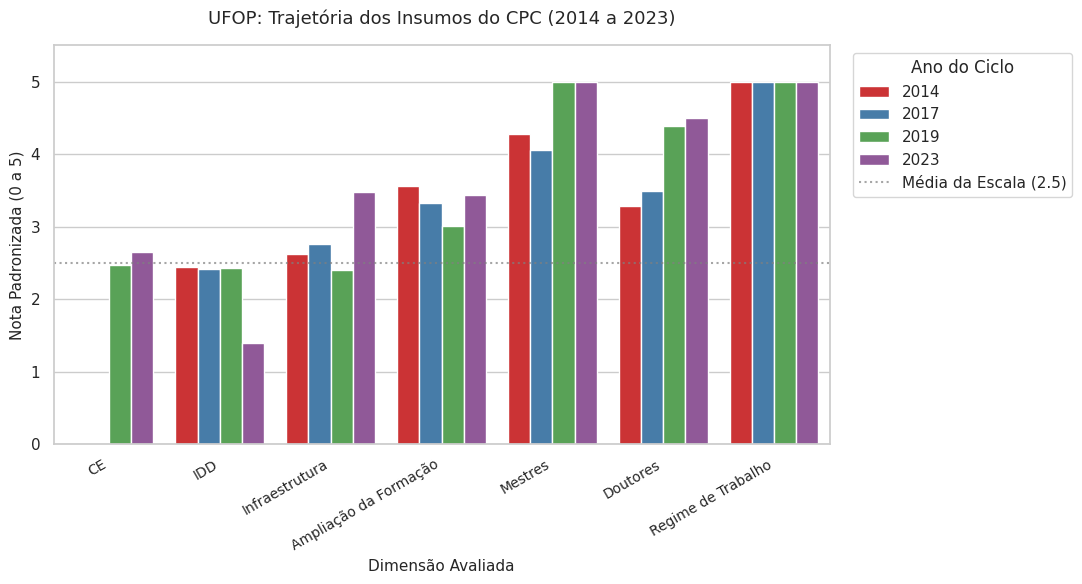

In [ ]:
colunas_validas = [c for c in insumos_ufop.columns if insumos_ufop[c].notna().sum() > 0 and c != "CPC (Contínuo)"]
df_plot_insumos = insumos_ufop[colunas_validas].melt(
    id_vars="Ano",
    var_name="Insumo",
    value_name="Nota Padronizada"
)

# Simplifica os nomes para o eixo X
df_plot_insumos["Insumo"] = df_plot_insumos["Insumo"].str.replace("Nota Padronizada - ", "")

plt.figure(figsize=(11, 6))

ax = sns.barplot(
    data=df_plot_insumos,
    x="Insumo",
    y="Nota Padronizada",
    hue="Ano",
    palette="Set1",
    errorbar=None
)

# Destaque visual: linha de média 2.5 (centro da escala)
plt.axhline(2.5, color="gray", linestyle=":", alpha=0.7, label="Média da Escala (2.5)")

plt.xticks(rotation=30, ha="right", fontsize=10)
plt.title("UFOP: Trajetória dos Insumos do CPC (2014 a 2023)", fontsize=13, pad=15)
plt.xlabel("Dimensão Avaliada", fontsize=11)
plt.ylabel("Nota Padronizada (0 a 5)", fontsize=11)
plt.ylim(0, 5.5)

plt.legend(title="Ano do Ciclo", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
from google.colab import files

caminho_arquivo_excel = 'resumo_analise_ufop.xlsx'

with pd.ExcelWriter(caminho_arquivo_excel, engine="openpyxl") as writer:
    # 1. Base consolidada geral (Sudeste)
    base_geral.to_excel(writer, sheet_name="Base_Completa", index=False)

    # 2. Resumo da evolução temporal regional
    evolucao.to_excel(writer, sheet_name="Evolucao_Temporal")

    # 3. Agrupamentos por Região e Estado
    por_regiao.to_excel(writer, sheet_name="Por_Regiao", index=False)
    por_estado.to_excel(writer, sheet_name="Por_Estado", index=False)

    # 4. Comparativo UFOP vs. Benchmarks (MG e Sudeste)
    df_comparacao.to_excel(writer, sheet_name="UFOP_x_MG_x_Sudeste", index=False)

    # 5. Top 5 cursos de Minas Gerais em 2023
    top5_mg.to_excel(writer, sheet_name="Top5_MG_2023", index=False)

    # 6. Decomposição detalhada dos insumos e componentes da UFOP
    insumos_ufop.to_excel(writer, sheet_name="Insumos_UFOP", index=False)

print("Relatório gerado com sucesso!")

# Faz o download automático da planilha para seu computador
files.download(caminho_arquivo_excel)

Relatório gerado com sucesso!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
!pip install gspread gspread_dataframe --quiet

from google.colab import auth
import gspread
from google.auth import default
from gspread_dataframe import set_with_dataframe

# 2. Autenticação na sua conta Google
auth.authenticate_user()
creds, _ = default()
gc = gspread.authorize(creds)

# 3. Cria a planilha no seu Google Drive
sh = gc.create('Base_ENADE_Controle_Automacao_UFOP')

# Aba 1: Base Completa (Sudeste)
ws1 = sh.sheet1
ws1.update_title("Base_Completa")
set_with_dataframe(ws1, base_geral)

# Aba 2: Evolução Temporal Geral
ws2 = sh.add_worksheet(title="Evolucao_Temporal", rows=len(evolucao)+15, cols=15)
set_with_dataframe(ws2, evolucao.reset_index())

# Aba 3: Por Região
ws3 = sh.add_worksheet(title="Por_Regiao", rows=len(por_regiao)+15, cols=15)
set_with_dataframe(ws3, por_regiao)

# Aba 4: Por Estado (Sudeste)
ws4 = sh.add_worksheet(title="Por_Estado", rows=len(por_estado)+15, cols=15)
set_with_dataframe(ws4, por_estado)

# Aba 5: UFOP x MG x Sudeste
ws5 = sh.add_worksheet(title="UFOP_MG_Sudeste", rows=len(df_comparacao)+15, cols=15)
set_with_dataframe(ws5, df_comparacao)

# Aba 6: Top 5 Cursos em MG (2023)
ws6 = sh.add_worksheet(title="Top5_MG_2023", rows=len(top5_mg)+15, cols=15)
set_with_dataframe(ws6, top5_mg)

# Aba 7: Insumos Detalhados da UFOP (IDD, Prova, Docentes, Infraestrutura)
ws7 = sh.add_worksheet(title="Insumos_UFOP", rows=len(insumos_ufop)+15, cols=15)
set_with_dataframe(ws7, insumos_ufop)

print("="*60)
print("Planilha criada e populada com sucesso no Google Drive!")
print("Acesse o link direto:", sh.url)
print("="*60)

Planilha criada e populada com sucesso no Google Drive!
Acesse o link direto: https://docs.google.com/spreadsheets/d/1zK9wbGX2Nqi7TxwxXYlPEHKSJ7hMolN69vmxoBfprWE


/tmp/ipykernel_3257/2133978466.py:192: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


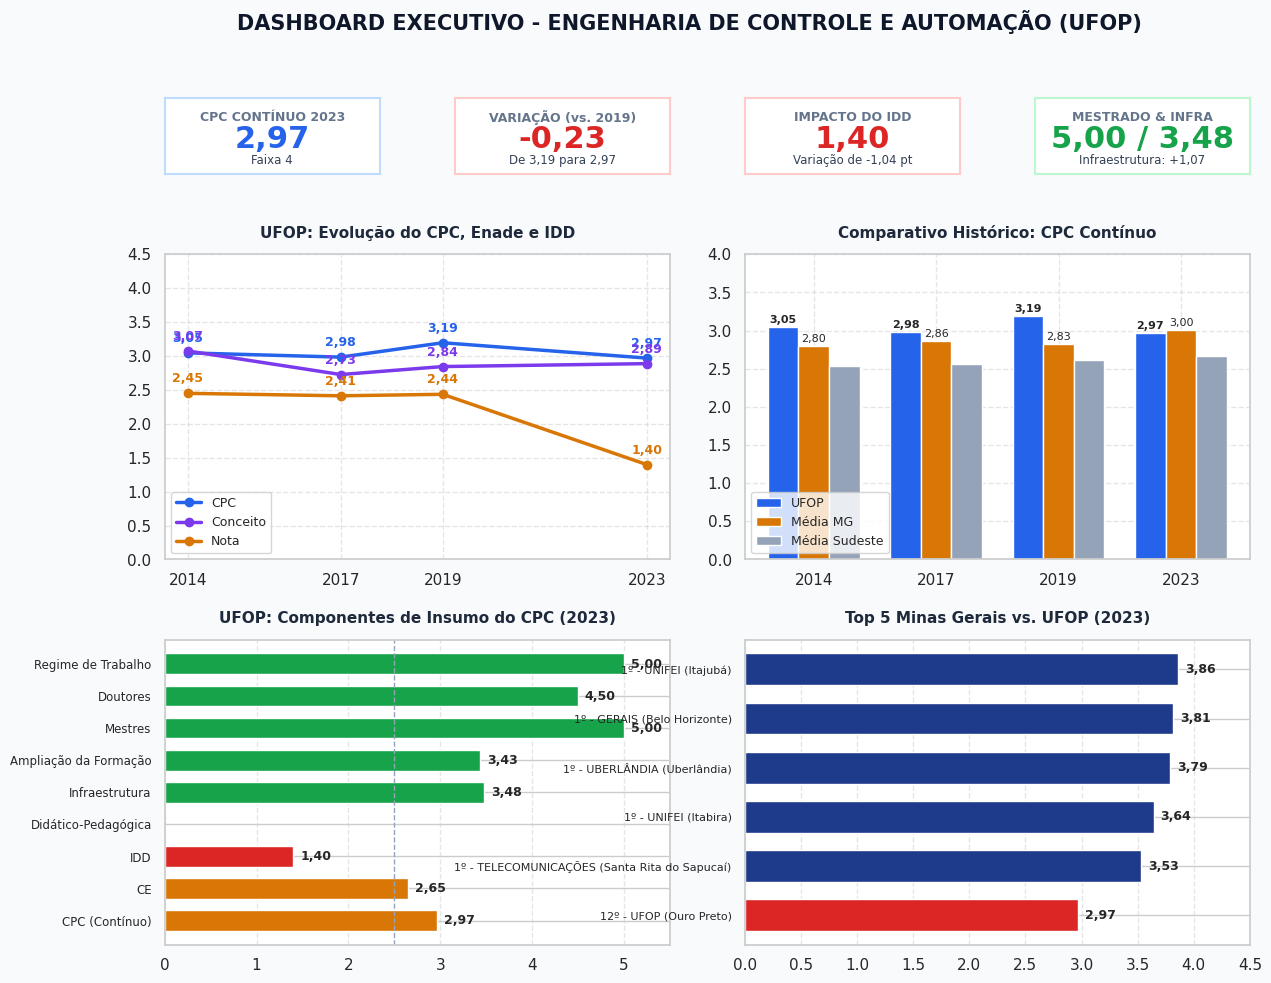

In [ ]:
# ============================================================
# PAINEL EXECUTIVO (versão dinâmica completa)
# Todos os números vêm das tabelas do notebook, nada digitado à mão.
# ============================================================
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np
import pandas as pd

# --- Parâmetros (ajustáveis para comparação) ---
ANO_ATUAL = 2023
ANO_ANTERIOR = 2019

# --- 0. Confere se as tabelas necessárias existem ---
necessarias = ["df_comparacao", "insumos_ufop", "ufop_historico",
               "por_estado", "top5_mg", "mg_2023_detalhado"]
faltando = [n for n in necessarias if n not in globals()]
if faltando:
    raise NameError(f"Rode antes as células que criam: {faltando}")

# --- Funções auxiliares ---
def fmt(x, n=2):
    return f"{x:.{n}f}".replace(".", ",")

def fmt_s(x, n=2):
    return f"{x:+.{n}f}".replace(".", ",")

def valor(df, ano, coluna):
    linha = df[df["Ano"] == ano]
    if linha.empty or pd.isna(linha[coluna].iloc[0]):
        raise ValueError(f"Sem dado de '{coluna}' para {ano}")
    return float(linha[coluna].iloc[0])

# ------------------------------------------------------------
# 1. CAPTURA DINÂMICA DE DADOS (KPIs)
# ------------------------------------------------------------
cpc_atual = valor(insumos_ufop, ANO_ATUAL, "CPC (Contínuo)")
cpc_ant = valor(insumos_ufop, ANO_ANTERIOR, "CPC (Contínuo)")
idd_atual = valor(insumos_ufop, ANO_ATUAL, "Nota Padronizada - IDD")
idd_ant = valor(insumos_ufop, ANO_ANTERIOR, "Nota Padronizada - IDD")
mest_atual = valor(insumos_ufop, ANO_ATUAL, "Nota Padronizada - Mestres")
infra_atual = valor(insumos_ufop, ANO_ATUAL, "Nota Padronizada - Infraestrutura")
infra_ant = valor(insumos_ufop, ANO_ANTERIOR, "Nota Padronizada - Infraestrutura")

var_cpc = cpc_atual - cpc_ant
var_idd = idd_atual - idd_ant
var_infra = infra_atual - infra_ant

faixa = ufop_historico.loc[ufop_historico["Ano"] == ANO_ATUAL, "CPC (Faixa)"].iloc[0]
try:
    faixa = int(float(faixa))
except (ValueError, TypeError):
    pass

VERDE, VERMELHO, AMBAR, AZUL = "#16A34A", "#DC2626", "#D97706", "#2563EB"
BORDA = {AZUL: "#BFDBFE", VERMELHO: "#FECACA", AMBAR: "#FDE68A", VERDE: "#BBF7D0"}

kpis = [
    {
        "title": f"CPC CONTÍNUO {ANO_ATUAL}",
        "val": fmt(cpc_atual),
        "sub": f"Faixa {faixa}",
        "color": AZUL
    },
    {
        "title": "VARIAÇÃO (vs. 2019)",
        "val": fmt_s(var_cpc),
        "sub": f"De {fmt(cpc_ant)} para {fmt(cpc_atual)}",
        "color": VERMELHO if var_cpc < 0 else VERDE
    },
    {
        "title": "IMPACTO DO IDD",
        "val": fmt(idd_atual),
        "sub": f"Variação de {fmt_s(var_idd)} pt",
        "color": VERMELHO if var_idd < -0.5 else (AMBAR if var_idd < 0 else VERDE)
    },
    {
        "title": "MESTRADO & INFRA",
        "val": f"{fmt(mest_atual)} / {fmt(infra_atual)}",
        "sub": f"Infraestrutura: {fmt_s(var_infra)}",
        "color": VERDE if var_infra > 0 else VERMELHO
    }
]

# ------------------------------------------------------------
# 2. CONFIGURAÇÃO DA FIGURA E GRID
# ------------------------------------------------------------
fig = plt.figure(figsize=(14, 11), facecolor="#F8FAFC")
gs = gridspec.GridSpec(3, 4, height_ratios=[0.25, 1, 1], hspace=0.35, wspace=0.35)

# --- Linha 0: KPI Cards ---
for idx, kpi in enumerate(kpis):
    ax_kpi = fig.add_subplot(gs[0, idx])
    ax_kpi.set_facecolor("#FFFFFF")
    ax_kpi.spines[["top", "bottom", "left", "right"]].set_color(BORDA[kpi["color"]])
    ax_kpi.spines[["top", "bottom", "left", "right"]].set_linewidth(1.5)
    ax_kpi.set_xticks([])
    ax_kpi.set_yticks([])

    ax_kpi.text(0.5, 0.75, kpi["title"], color="#64748B", fontsize=9, fontweight="bold", ha="center", va="center")
    ax_kpi.text(0.5, 0.45, kpi["val"], color=kpi["color"], fontsize=22, fontweight="black", ha="center", va="center")
    ax_kpi.text(0.5, 0.18, kpi["sub"], color="#334155", fontsize=8.5, fontweight="medium", ha="center", va="center")

# --- Quadrante 1 (gs[1, 0:2]): Evolução de Indicadores da UFOP ---
ax1 = fig.add_subplot(gs[1, 0:2])
indicadores = ["CPC (Contínuo)", "Conceito Enade (Contínuo)", "Nota Padronizada - IDD"]
cores_ind = [AZUL, "#7C3AED", AMBAR]

for col_ind, cor in zip(indicadores, cores_ind):
    serie_ind = ufop_historico.set_index("Ano")[col_ind]
    ax1.plot(serie_ind.index, serie_ind.values, marker="o", linewidth=2.5, color=cor, label=col_ind.split(" ")[0])
    for x, y in zip(serie_ind.index, serie_ind.values):
        if not np.isnan(y):
            ax1.annotate(fmt(y), (x, y), textcoords="offset points", xytext=(0,8), ha="center", fontsize=9, fontweight="bold", color=cor)

ax1.set_title("UFOP: Evolução do CPC, Enade e IDD", fontsize=11, fontweight="bold", color="#1E293B", pad=12)
ax1.set_ylim(0, 4.5)
ax1.set_xticks(ufop_historico["Ano"].unique())
ax1.legend(loc="lower left", fontsize=9)
ax1.grid(True, linestyle="--", alpha=0.5)

# --- Quadrante 2 (gs[1, 2:4]): Comparativo de Benchmarks ---
ax2 = fig.add_subplot(gs[1, 2:4])
bar_width = 0.25
anos = df_comparacao["Ano"].values
x_pos = np.arange(len(anos))

ax2.bar(x_pos - bar_width, df_comparacao["UFOP"], width=bar_width, label="UFOP", color=AZUL)
ax2.bar(x_pos, df_comparacao["Média MG"], width=bar_width, label="Média MG", color=AMBAR)
ax2.bar(x_pos + bar_width, df_comparacao["Média Sudeste"], width=bar_width, label="Média Sudeste", color="#94A3B8")

for idx_ano in range(len(anos)):
    ax2.annotate(fmt(df_comparacao["UFOP"].iloc[idx_ano]), (x_pos[idx_ano] - bar_width, df_comparacao["UFOP"].iloc[idx_ano]), textcoords="offset points", xytext=(0,3), ha="center", fontsize=8, fontweight="bold")
    ax2.annotate(fmt(df_comparacao["Média MG"].iloc[idx_ano]), (x_pos[idx_ano], df_comparacao["Média MG"].iloc[idx_ano]), textcoords="offset points", xytext=(0,3), ha="center", fontsize=8)

ax2.set_title("Comparativo Histórico: CPC Contínuo", fontsize=11, fontweight="bold", color="#1E293B", pad=12)
ax2.set_xticks(x_pos)
ax2.set_xticklabels(anos)
ax2.set_ylim(0, 4.0)
ax2.legend(loc="lower left", fontsize=9)
ax2.grid(True, linestyle="--", alpha=0.5)

# --- Quadrante 3 (gs[2, 0:2]): Insumos Detalhados da UFOP ---
ax3 = fig.add_subplot(gs[2, 0:2])
insumos_cols = [c for c in insumos_ufop.columns if c != "Ano"]
valores_atuais = insumos_ufop.loc[insumos_ufop["Ano"] == ANO_ATUAL, insumos_cols].values[0]
labels_ins = [c.replace("Nota Padronizada - ", "") for c in insumos_cols]

y_pos = np.arange(len(labels_ins))
bar_colors = [VERMELHO if v < 2.0 else (AMBAR if v < 3.0 else VERDE) for v in valores_atuais]

rects = ax3.barh(y_pos, valores_atuais, color=bar_colors, height=0.65)
ax3.axvline(2.5, color="#94A3B8", linestyle="--", linewidth=1, label="Média da Escala")

for rect in rects:
    width = rect.get_width()
    if not np.isnan(width):
        ax3.annotate(fmt(width), (width, rect.get_y() + rect.get_height()/2.), xytext=(5, 0), textcoords="offset points", ha="left", va="center", fontsize=9, fontweight="bold")

ax3.set_title(f"UFOP: Componentes de Insumo do CPC ({ANO_ATUAL})", fontsize=11, fontweight="bold", color="#1E293B", pad=12)
ax3.set_yticks(y_pos)
ax3.set_yticklabels(labels_ins, fontsize=8.5)
ax3.set_xlim(0, 5.5)
ax3.grid(True, axis="x", linestyle="--", alpha=0.5)

# --- Quadrante 4 (gs[2, 2:4]): Top 5 MG 2023 vs UFOP ---
ax4 = fig.add_subplot(gs[2, 2:4])

top_nomes = ["1º - " + r["Nome da IES"].split(" ")[-1] + f" ({r['Município do Curso']})" for _, r in top5_mg.iterrows()]
top_vals = list(top5_mg["CPC (Contínuo)"].values)

top_nomes.append("12º - UFOP (Ouro Preto)")
top_vals.append(cpc_atual)

y_pos_top = np.arange(len(top_nomes))
cores_top = ["#1E3A8A"] * 5 + [VERMELHO]

rects_top = ax4.barh(y_pos_top, top_vals, color=cores_top, height=0.65)
ax4.invert_yaxis() # Top 1 no topo

for rect in rects_top:
    width = rect.get_width()
    ax4.annotate(fmt(width), (width, rect.get_y() + rect.get_height()/2.), xytext=(5, 0), textcoords="offset points", ha="left", va="center", fontsize=9, fontweight="bold")

ax4.set_title(f"Top 5 Minas Gerais vs. UFOP ({ANO_ATUAL})", fontsize=11, fontweight="bold", color="#1E293B", pad=12)
ax4.set_yticks(y_pos_top)
ax4.set_yticklabels(top_nomes, fontsize=8)
ax4.set_xlim(0, 4.5)
ax4.grid(True, axis="x", linestyle="--", alpha=0.5)

plt.suptitle("DASHBOARD EXECUTIVO - ENGENHARIA DE CONTROLE E AUTOMAÇÃO (UFOP)", fontsize=15, fontweight="black", color="#0F172A", y=0.96)
plt.tight_layout()
plt.savefig("dashboard_proativa_ufop_hd.png", dpi=300, bbox_inches="tight")
plt.show()
